# 2D Slice of environment and rays

In [2]:
from n23_fluctuations_ragland import tools
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cmocean
import seaborn as sns
import pickle
from dotenv import find_dotenv, load_dotenv
import os
load_dotenv(find_dotenv())

%config InlineBackend.figure_format = 'retina'

In [3]:
whoi_colors = ['#00B7BD', '#EE5340', '#0069b1', '#041e42']

In [4]:
dss = tools.open_receptions()

100%|██████████████████████████████████████████████████████████████████████████████████| 23/23 [00:20<00:00,  1.15it/s]


In [5]:
fctd_raw = tools.compute_filtered_fctd_grid(None, None)
fctd_smooth = tools.compute_filtered_fctd_grid(z_smooth=200, r_smooth=15000)

fctd_raw = fctd_raw.assign_coords({'range':(fctd_raw.range.values + 35e3)/1000})
fctd_smooth = fctd_smooth.assign_coords({'range':(fctd_smooth.range.values + 35e3)/1000})

fctd_smooth = fctd_smooth.interpolate_na('depth')

/Users/john/Code/NESCAFE/NESCAFE23/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)
/Users/john/Code/NESCAFE/NESCAFE23/.venv/lib/python3.13/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)


In [6]:
fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/ray_run_forward_back.pkl"

with open(fn, "rb") as f:
    ray_run = pickle.load(f)

rays = ray_run["rays"]
rays_back = ray_run["rays_back"]
eigs = ray_run["eigs"]
eigs_back = ray_run["eigs_back"]
envi = ray_run["envi"]
envi_back = ray_run["envi_back"]

In [7]:
ray_ids_plot = ['+7', '-7', '-6', '+6', '-8']
#ray_ids_plot = ['-8','+7', '-7']

In [8]:
sns.set_palette("Set2")
sns.color_palette("Set2")

[(0.4, 0.7607843137254902, 0.6470588235294118),
 (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
 (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
 (0.9058823529411765, 0.5411764705882353, 0.7647058823529411),
 (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
 (1.0, 0.8509803921568627, 0.1843137254901961),
 (0.8980392156862745, 0.7686274509803922, 0.5803921568627451),
 (0.7019607843137254, 0.7019607843137254, 0.7019607843137254)]

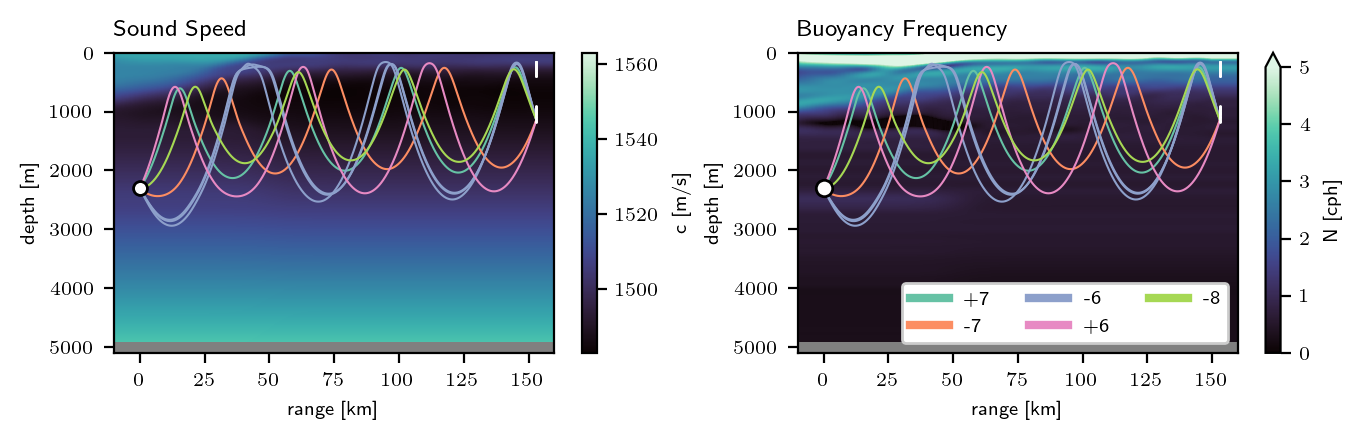

In [10]:
plt.rcParams.update({'font.size':'7'})
plt.rcParams.update({"text.usetex": True})

fig, axes = plt.subplots(1,2, figsize=(6.67, 2))
axes = axes.flatten()

plt.sca(axes[0])
fctd_smooth['c'].plot(cmap='mako', rasterized=True)
plt.title('Sound Speed', loc='left')

for ray_id_idx, ray_id in enumerate(ray_ids_plot):
    for k in range(len(tools.EIG_INDEXS[ray_id])):
        ray_id_pr, (sign, number, suffix) = tools.parse_ray_id(ray_id)
        eig_idx = np.where(eigs.ray_id[0] == ray_id_pr)[0][tools.EIG_INDEXS[ray_id][k][0]]
        #plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='w', lw=2, alpha=0.5)
        plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c=f'C{ray_id_idx}', lw=0.75, alpha=1)

plt.fill_between(fctd_smooth.range, 10000,4908, lw=0, color='gray')

# plot moorings
plt.scatter(x=[153] * 60, y=dss[4].actual_depth.values, c="w", lw=0, s=1, zorder=100)
plt.scatter(x=0, y=2300, s=25, lw=1, c="w", edgecolor="k", zorder=100)

plt.xlim([-10, 160])
plt.ylim([5100,0])
plt.xlabel('range [km]')
plt.ylabel('depth [m]')

plt.sca(axes[1])
fctd_smooth['N'].plot(cmap='mako', vmin=0, vmax=5, rasterized=True)

plt.title('Buoyancy Frequency', loc='left')

for ray_id_idx, ray_id in enumerate(ray_ids_plot):
    for k in range(len(tools.EIG_INDEXS[ray_id])):
        ray_id_pr, (sign, number, suffix) = tools.parse_ray_id(ray_id)
        eig_idx = np.where(eigs.ray_id[0] == ray_id_pr)[0][tools.EIG_INDEXS[ray_id][k][0]]
        #plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='w', lw=2, alpha=0.5)
        if k == 0:
            ray_id_label = ray_id
        else:
            ray_id_label=None
        plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c=f"C{ray_id_idx}", label=ray_id_label, lw=0.75, alpha=1)

leg = plt.legend(loc='lower right', ncols=3, framealpha=1)

for line in leg.get_lines():
    line.set_linewidth(3)
    
plt.fill_between(fctd_smooth.range, 10000,4908, lw=0, color='gray')

# plot moorings
plt.scatter(x=[153] * 60, y=dss[4].actual_depth.values, c="w", lw=0, s=1, zorder=100)
plt.scatter(x=0, y=2300, s=35, lw=1, c="w", edgecolor="k", zorder=100)

plt.xlim([-10, 160])
plt.ylim([5100,0])
plt.xlabel('range [km]')
plt.ylabel('depth [m]')

plt.tight_layout(pad=0)

plt.savefig('../../figures/2D_slice.pdf', dpi=300)
#plt.show()

In [ ]:
for line in leg.get_lines():
    line.set_linewidth(3)

In [ ]:
fctd_smooth['c'].plot(cmap='mako', rasterized=True)
plt.title('Sound Speed', loc='left')

for ray_id in ray_ids_plot:
    ray_id_pr, (sign, number, suffix) = tools.parse_ray_id(ray_id)
    eig_idx = np.where(eigs.ray_id[0] == ray_id_pr)[0][tools.EIG_INDEXS[ray_id][0][0]]
    #plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='w', lw=2, alpha=0.5)
    plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='w', lw=0.5, alpha=1)

plt.fill_between(fctd_smooth.range, 10000,4908, lw=0, color='gray')

# plot moorings
plt.scatter(x=[153] * 60, y=dss[4].actual_depth.values, c="w", lw=0, s=1, zorder=100)
plt.scatter(x=0, y=2300, s=25, lw=1, c="w", edgecolor="k", zorder=100)

plt.xlim([-1, 5])
plt.ylim([3000,2000])
plt.xlabel('range [km]')
plt.ylabel('depth [m]')

In [ ]:
ray_ids_plot = ['-6', '+6', '-7']

plt.rcParams.update({'font.size':'8'})
plt.rcParams.update({"text.usetex": True})

fig = plt.figure(figsize=(3.37, 2))
fctd_smooth['c'].plot(cmap='mako', rasterized=True)

for ray_id in ray_ids_plot:
    for k in range(len(tools.EIG_INDEXS[ray_id])):
        ray_id_pr, (sign, number, suffix) = tools.parse_ray_id(ray_id)
        eig_idx = np.where(eigs.ray_id[0] == ray_id_pr)[0][tools.EIG_INDEXS[ray_id][k][0]]
        #plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='w', lw=2, alpha=0.5)
        plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='w', lw=0.5, alpha=1)


plt.fill_between(fctd_smooth.range, 10000,4908, lw=0, color='gray')

# plot moorings
plt.scatter(x=[153] * 60, y=dss[4].actual_depth.values, c="w", lw=0, s=1, zorder=100)
plt.scatter(x=0, y=2300, s=25, lw=1, c="w", edgecolor="k", zorder=100)

plt.xlim([-10, 160])
plt.ylim([5100,0])
plt.xlabel('range [km]')
plt.ylabel('depth [m]')
plt.title('')

In [ ]:
fctd_smooth['c'].plot(cmap='mako', rasterized=True)
plt.title('Sound Speed', loc='left')

for ray_id in ray_ids_plot:
    ray_id_pr, (sign, number, suffix) = tools.parse_ray_id(ray_id)
    eig_idx = np.where(eigs.ray_id[0] == ray_id_pr)[0][tools.EIG_INDEXS[ray_id][0][0]]
    #plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='w', lw=2, alpha=0.5)
    plt.plot(eigs.rs[0][eig_idx,:]/1000, -eigs.zs[0][eig_idx,:], c='w', lw=0.5, alpha=1)

plt.fill_between(fctd_smooth.range, 10000,4908, lw=0, color='gray')

# plot moorings
plt.scatter(x=[153] * 60, y=dss[4].actual_depth.values, c="w", lw=0, s=1, zorder=100)
plt.scatter(x=0, y=2300, s=25, lw=1, c="w", edgecolor="k", zorder=100)

plt.xlim([-10, 160])
plt.ylim([5100,0])
plt.xlabel('range [km]')
plt.ylabel('depth [m]')